# NumPy und Pandas: Schiefe Daten, Schätzen und Monte-Carlo
### Unterrichtsmaterial | Julia Brutskaya | FIDP / Daten- und Prozessanalyse

---
**Kontext:** Wahrscheinlichkeitsrechnung, Tag 5 – schiefe Verteilungen, Schätzen und Simulieren<br>
**Bibliotheken:** `numpy`, `pandas`, `matplotlib`, optional `scipy`

<img src="png%20Dateien/herr_bauchgefuehl.png" alt="Herr Bauchgefühl" width="120"> <img src="png%20Dateien/etta_elster.png" alt="Etta" width="120"> <img src="png%20Dateien/nils_eichhoernchen.png" alt="Nils" width="120"> <img src="png%20Dateien/mats_maulwurf_huegel.png" alt="Mats" width="120"> <img src="png%20Dateien/fiete_fuchs.png" alt="Fiete" width="120">

Heute Vormittag ging es um schiefe Verteilungen, Transformationen, das Schätzen von Parametern und die Monte-Carlo-Simulation. Heute Nachmittag messen wir die Form von Daten mit Pandas, schreiben Auswertungen als Kette und simulieren ein ganzes Projekt mit einer Zeile NumPy.

| Block | Inhalt | Neu |
|---|---|---|
| A | Die Form messen | `skew()`, `kurt()`, `quantile([…])`, Modus über Klassen |
| B | Zwei Gipfel und Method Chaining | `rng.lognormal`, Log-Achse, `assign`, `pipe`, Ketten in Klammern |
| C | Transformieren | `np.log10`, `np.log1p`, `np.sqrt`, Rücktransformation |
| D | Parameter schätzen | Likelihood-Gitter mit `argmax`/`idxmax`, `std(ddof=0)`, wiederholte Stichproben, Bootstrap |
| E | Monte-Carlo vektorisiert | 2D-Arrays, `sum(axis=1)`, `rng.triangular`, `pd.cut` mit `labels`, ECDF |
| F | Weitere Übungen | Kennzahlen lesen, Underflow, π, Projekt von Hand, Ergebnis lesen, Box-Cox |

---
# Block A – Die Form messen

## 1 – Die Daten des Tages

Wir erzeugen zwei Datensätze, beide mit Antwortzeiten einer API:

- `api`: Anfragen mit Cache. 80 % kommen aus dem Cache (rund 5 ms), 20 % gehen an die Datenbank (rund 150 ms). Zwei Gipfel, für Block B.
- `lat`: eine schiefe Latenz mit einem Gipfel, Median 30 ms.

Neu ist `rng.lognormal(mean, sigma)`. Die Werte sind **log-normalverteilt**: Ihr Logarithmus ist normalverteilt.

> **Achtung:** `mean` und `sigma` beziehen sich auf die **Logarithmen** (ln), nicht auf die Daten. `mean=np.log(30)` heißt: Median 30 ms. Der Mittelwert liegt höher.

In [132]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

GELB, GRUEN, ROT, GRAU = "#e0a800", "#2e9e44", "#d62828", "#c8c8c8"   # Igel-Drillinge: Modus, Median, Mittelwert

rng = np.random.default_rng(42)
n = 10_000
cache = rng.choice(["hit", "miss"], size=n, p=[0.8, 0.2])
ms = np.where(cache == "hit", rng.lognormal(np.log(5), 0.3, n), rng.lognormal(np.log(150), 0.25, n))
api = pd.DataFrame({"cache": cache, "ms": ms.round(1)})

lat = pd.Series(rng.lognormal(np.log(30), 0.8, n).round(1), name="ms")
lat.head()

0    18.2
1    20.4
2    10.0
3    29.1
4    24.2
Name: ms, dtype: float64

## 2 – Mittelwert, Median und Schiefe

<img src="png%20Dateien/herr_bauchgefuehl.png" alt="Herr Bauchgefühl" width="110">

> **Herr Bauchgefühl:** „Unsere API braucht im Durchschnitt 41 Millisekunden. Eine typische Anfrage dauert also 41 Millisekunden."

`skew()` kennt ihr seit gestern. Neu ist `kurt()` für die **Wölbung**.

In [133]:
print("Mittelwert:", round(lat.mean(), 1), "| Median:", lat.median())
print("Schiefe:   ", round(lat.skew(), 2), "| Wölbung:", round(lat.kurt(), 1))

Mittelwert: 41.3 | Median: 29.7
Schiefe:    4.54 | Wölbung: 52.9


Mittelwert > Median und Schiefe weit über 1: stark rechtsschief. Die Wölbung ist riesig, weil es einige sehr lange Anfragen gibt (fette Ränder).

> **Achtung:** Pandas `kurt()` liefert schon die **Überschuss-Wölbung** (Exzess), Normalverteilung = 0, wie im Skript. Wer im Internet „Normalverteilung hat Kurtosis 3" liest, meint die Rohform ohne − 3.

Zum Vergleich drei Verteilungen aus Notebook 11, dazu die Laplace-Verteilung mit spitzem Gipfel und fetten Rändern:

In [134]:
rng = np.random.default_rng(5)
woelbung = pd.DataFrame({
    "normal":  rng.normal(0, 1, n),
    "gleich":  rng.uniform(0, 1, n),
    "laplace": rng.laplace(0, 1, n),
})
woelbung.kurt().round(5)

normal    -0.02747
gleich    -1.23506
laplace    2.75434
dtype: float64

Normal ≈ 0 (mesokurtisch), gleich ≈ −1,2 (platykurtisch, keine Ränder), Laplace ≈ 3 (leptokurtisch, fette Ränder).

## 3 – Perzentile statt Mittelwert: `quantile`

Mit einer **Liste** gibt `quantile` mehrere Perzentile auf einmal zurück. Im Monitoring berichtet man Latenz genau so: P50, P90, P95, P99.

In [135]:
lat.quantile([0.5, 0.9, 0.95, 0.99]).round(1)

0.50     29.7
0.90     84.5
0.95    112.2
0.99    191.5
Name: ms, dtype: float64

Lesart: 95 % aller Anfragen sind nach 112 ms fertig, 5 % brauchen länger. Das sagt einem Team viel mehr als „im Mittel 41 ms".

## 4 – Die Lageregel als Grafik

Bei stetigen Daten kommt fast jeder Wert nur einmal vor, `mode()` hilft also nicht. Den **Modus** bestimmen wir über Klassen: mit `pd.cut` in 5-ms-Klassen einteilen, die häufigste Klasse suchen und ihre Mitte (`.mid`) nehmen.

häufigste Klasse: (15, 20] | Modus ≈ 17.5


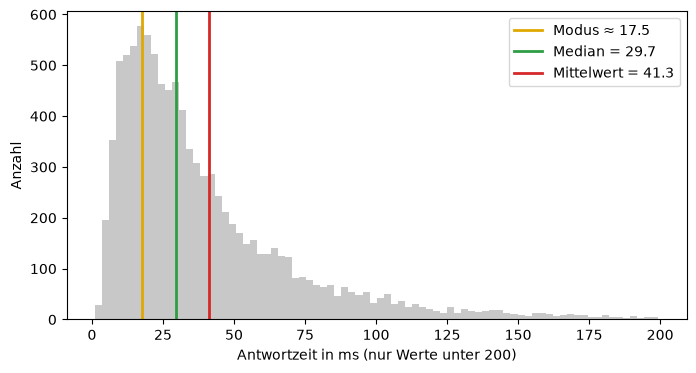

In [136]:
klasse = pd.cut(lat, bins=range(0, 1001, 5)).value_counts().idxmax()
modus = klasse.mid
print("häufigste Klasse:", klasse, "| Modus ≈", modus)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(lat[lat < 200], bins=80, color=GRAU)
ax.axvline(modus, color=GELB, linewidth=2, label=f"Modus ≈ {modus}")
ax.axvline(lat.median(), color=GRUEN, linewidth=2, label=f"Median = {lat.median()}")
ax.axvline(lat.mean(), color=ROT, linewidth=2, label=f"Mittelwert = {lat.mean():.1f}")
ax.set_xlabel("Antwortzeit in ms (nur Werte unter 200)")
ax.set_ylabel("Anzahl")
ax.legend()
plt.show()

<img src="png%20Dateien/drilling_modus.png" alt="Modus" width="80"> <img src="png%20Dateien/drilling_median.png" alt="Median" width="80"> <img src="png%20Dateien/drilling_mittelwert.png" alt="Mittelwert" width="80">

Modus < Median < Mittelwert: Die Igel-Drillinge stehen genau so, wie die Lageregel es für rechtsschiefe Daten vorhersagt. Der Mittelwert wird vom langen Ausläufer nach rechts gezogen.

### Übung 1

Herr Bauchgefühl will im Team-Meeting die Latenz aus `lat` vorstellen.

- **a)** Welcher Anteil der Anfragen ist **schneller** als der Mittelwert? Was sagt das über die „typische" Anfrage?
- **b)** Erstelle einen kleinen Bericht als Series mit den Einträgen `median`, `p90`, `p95`, `p99` und `max`.
- **c)** Die Zielvorgabe lautet: „95 % aller Anfragen unter 100 ms." Wird sie erreicht? Welcher Anteil liegt tatsächlich unter 100 ms?
- **d)** Was sagst du Herrn Bauchgefühl?

In [137]:
# a) Anteil unter Mittelwert
print(round((lat < lat.mean()).mean(), 3))


0.66


In [138]:
# b) Perzentil-Bericht
q = lat.quantile([0.5, 0.9, 0.95, 0.99])
bericht = pd.Series({"median": q[0.5], "p90": q[0.9], "p95": q[0.95], "p99": q[0.99], "max": lat.max()})
bericht.round(2)

median     29.7
p90        84.5
p95       112.2
p99       191.5
max       956.0
dtype: float64

In [139]:
# c) Zielvorgabe
print("Anteil unter 100ms", round((lat < 100).mean(), 3))


Anteil unter 100ms 0.931


In [140]:
# d) Mittelwert ist keine typische Anfrage, Ausreißer sensitiv (langsamen Antworten)
#    Median ist typisch, für das Ziel zähl P95


---
# Block B – Zwei Gipfel und Method Chaining

## 5 – Der Mittelwert im Tal

<img src="png%20Dateien/etta_elster.png" alt="Etta" width="110">

**Etta:** „Die Antwortzeiten haben zwei Gipfel, einen bei 5 und einen bei 150 Millisekunden. Bevor ich irgendetwas mittele, sortiere ich lieber in zwei Gruppen."

In [141]:
print("Mittelwert:", round(api["ms"].mean(), 1), "| Median:", api["ms"].median())
print()
print(api.groupby("cache")["ms"].agg(["count", "mean", "median"]).round(1))
print()
print(api["cache"].value_counts(normalize=True).round(3))

Mittelwert: 34.7 | Median: 5.5

       count   mean  median
cache                      
hit     8046    5.3     5.0
miss    1954  155.9   151.1

cache
hit     0.805
miss    0.195
Name: proportion, dtype: float64


Der Gesamtmittelwert von rund 35 ms liegt **im Tal**: Fast keine Anfrage dauert so lange. Er ist das **gewichtete** Mittel der beiden Gruppen (Statistik 2, „Mittelwert von Mittelwerten"):

In [142]:
gruppen = api.groupby("cache")["ms"].agg(["count", "mean"])
gewichtet = (gruppen["count"] * gruppen["mean"]).sum() / gruppen["count"].sum()
print(round(gewichtet, 1))

34.7


## 6 – Die Log-Achse

Auf einer normalen Achse ist der Cache-Gipfel nur ein schmaler Strich bei 5 ms. Mit `ax.set_xscale("log")` bekommt jede Zehnerpotenz gleich viel Platz. Damit die Balken auf der Log-Achse gleich breit aussehen, legen wir die Klassengrenzen mit `np.logspace` fest: 60 Grenzen von 10⁰ = 1 bis 10^2,7 ≈ 500 ms.

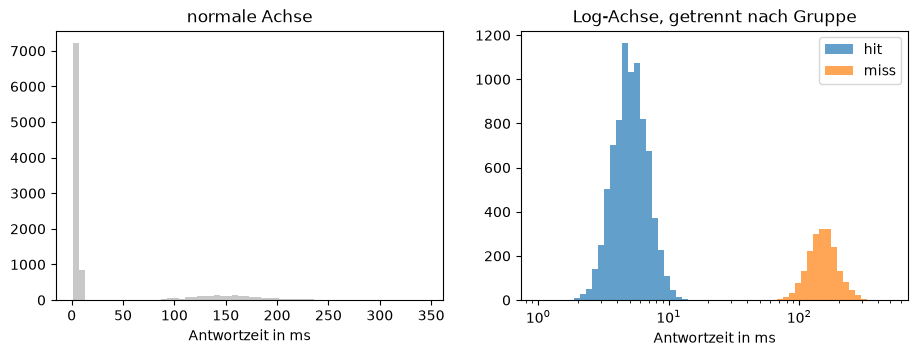

In [143]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

axes[0].hist(api["ms"], bins=60, color=GRAU)
axes[0].set_title("normale Achse")

for gruppe, teil in api.groupby("cache"):
    axes[1].hist(teil["ms"], bins=np.logspace(0, 2.7, 60), alpha=0.7, label=gruppe)
axes[1].set_xscale("log")
axes[1].set_title("Log-Achse, getrennt nach Gruppe")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Antwortzeit in ms")
plt.show()

> **Achtung:** Die Log-Achse ändert nur das **Bild**. Die Daten bleiben gleich, `skew()` bleibt gleich. In Block C ändern wir die Daten selbst.

## 7 – Method Chaining: eine Auswertung als Kette

Bisher habt ihr Zwischenergebnisse in Variablen gespeichert. Bei vielen Schritten wird das unübersichtlich. Pandas erlaubt, Methoden **aneinanderzuhängen**: Jede Methode gibt einen DataFrame zurück, auf den die nächste wirkt.

Neu ist `assign`: Es legt neue Spalten an und gibt eine **Kopie** zurück, das Original bleibt unverändert.

In [144]:
bericht = (
    api
    .assign(log_ms=lambda d: np.log10(d["ms"]), langsam=lambda d: d["ms"] > 100)
    .groupby("cache")
    .agg(anzahl=("ms", "size"),
         median_ms=("ms", "median"),
         anteil_langsam=("langsam", "mean"))
    .round(2)
)
bericht

,anzahl,median_ms,anteil_langsam
cache,,,
hit,8046,5.0,0.00
miss,1954,151.1,0.95


So liest man die Kette: Nimm `api`, füge zwei Spalten hinzu, gruppiere nach `cache`, berechne drei Kennzahlen, runde.

Drei Regeln:

- **Klammern um die ganze Kette.** Sonst endet die Anweisung am Zeilenende und es kommt ein `SyntaxError`.
- **Eine Methode pro Zeile**, mit dem Punkt am Zeilenanfang. Zum Debuggen kann man eine Zeile auskommentieren.
- **`lambda d:` in `assign`.** `d` ist der DataFrame **an dieser Stelle der Kette**. Ohne `lambda` würde `api["ms"]` auf das Original zeigen. Neue Spaltennamen sind Schlüsselwörter, also ohne Leerzeichen und Bindestriche.

In [145]:
print(api.columns.tolist())   # das Original hat keine neuen Spalten bekommen

['cache', 'ms']


## 8 – Eigene Funktionen in die Kette: `pipe`

`pipe(funktion)` übergibt das aktuelle Objekt an eine eigene Funktion. So lassen sich auch Funktionen in eine Kette hängen, die keine Pandas-Methode sind.

In [146]:
def schiefe_bericht(s):
    return pd.Series({"mittel": s.mean(), "median": s.median(), "schiefe": s.skew()}).round(2)

print(lat.pipe(schiefe_bericht))
print()
print(lat.pipe(np.log10).pipe(schiefe_bericht))

mittel     41.33
median     29.70
schiefe     4.54
dtype: float64

mittel     1.47
median     1.47
schiefe    0.02
dtype: float64


`lat.pipe(f)` ist dasselbe wie `f(lat)`. Der Vorteil zeigt sich in der zweiten Zeile: Man liest von links nach rechts „nimm `lat`, logarithmiere, erstelle den Bericht" statt von innen nach außen `schiefe_bericht(np.log10(lat))`.

### Übung 2

Übung 4 vom Vormittag: Nach einem Cache-Umbau sind 95 % der Anfragen Cache-Hits.

- **a)** Erzeuge `api95` wie in Abschnitt 1, aber mit `p=[0.95, 0.05]` (`rng = np.random.default_rng(4)`).
- **b)** Berechne Mittelwert und Median. Wie ändert sich der Mittelwert gegenüber 80 % Hits? Vergleiche mit der Rechnung aus dem Skript (0,95 · 5 + 0,05 · 150).
- **c)** Schreibe **eine Kette**, die für `api95` pro Gruppe `anzahl`, `median_ms` und `p95_ms` berechnet. *Hinweis: `p95_ms=("ms", lambda s: s.quantile(0.95))`.*
- **d)** Wie sollte man die Antwortzeiten stattdessen berichten?

In [147]:
# a) neue Daten
rng = np.random.default_rng(4)
cache95 = rng.choice(["hit", "miss"], size=n, p=[0.95, 0.05])
ms95 = np.where(cache95 == "hit", rng.lognormal(np.log(5), 0.3, n), rng.lognormal(np.log(150), 0.25, n))
# mean: log(5) - typisch 5 ms e^1,609=5 der Median der Daten           -> np.log(Median)
# sigma: 0.3 68%-Regel: ln(5)+/-0,3 (e^0,3=1,35): 68% liegen zwischen 5 / 1,35= 3,7ms und 5 * 1,35= 6,7ms
#        0.25                          (e^0,25=1,28)                150 / 1,28= 117ms und 150 * 1,28= 193ms       
api95 = pd.DataFrame({"cache": cache95, "ms": ms95.round(1)})
api95.head()



,cache,ms
0,hit,3.0
1,hit,4.0
2,miss,102.1
3,hit,4.8
4,hit,5.5


In [148]:
# b) Mittelvert und Median
print("95 % Hits", round(api95["ms"].mean(), 1), api95["ms"].median())
print("80 % Hits", round(api["ms"].mean(), 1), api["ms"].median())
print("Skript", 0.95 * 5 + 0.05 * 150)                              # kleiner, weil in py steuen die Werte um 5 und 150


95 % Hits 12.9 5.1
80 % Hits 34.7 5.5
Skript 12.25


In [149]:
# c) Bericht als Kette
(
    api95
    .groupby("cache")
    .agg(anzahl=("ms", "size"),
         median_ms=("ms", "median"),
         p95_ms =("ms", lambda s: s.quantile(0.95)))
    .round(1)
)


,anzahl,median_ms,p95_ms
cache,,,
hit,9483,5.0,8.2
miss,517,148.7,221.1


In [150]:
# d) nach Gruppen: Hit-Rate, Median der Hits, Median der Misses, P95 gesamt


---
# Block C – Transformieren

## 9 – Der Logarithmus zählt Nullen

<img src="png%20Dateien/nils_eichhoernchen.png" alt="Nils" width="110">

**Nils:** „Ich zähle einfach die Nullen: 10, 100, 1000 sind 1, 2, 3. Der Mittelwert ist 2, zurück sind das 100. Das ist ja der Median!"

NumPy-Funktionen wie `np.log10` wirken direkt auf eine ganze Series. Der Index bleibt erhalten.

In [151]:
drei = pd.Series([10, 100, 1000])
print(np.log10(drei).tolist())
print("Mittelwert:", drei.mean(), "| zurückgerechnet:", 10 ** np.log10(drei).mean())

[1.0, 2.0, 3.0]
Mittelwert: 370.0 | zurückgerechnet: 100.0


**Rücktransformation:** 10 hoch Mittelwert der Logarithmen ergibt **nicht** den Mittelwert 370, sondern das **geometrische Mittel** 100. Bei log-normalverteilten Daten liegt das nahe am Median.

Dasselbe mit `lat`:

In [152]:
lg = np.log10(lat)
print("Schiefe vorher:", round(lat.skew(), 2), "| nachher:", round(lg.skew(), 2))
print("zurückgerechnet:", round(10 ** lg.mean(), 1), "| Median:", lat.median(), "| Mittelwert:", round(lat.mean(), 1))

Schiefe vorher: 4.54 | nachher: 0.02
zurückgerechnet: 29.8 | Median: 29.7 | Mittelwert: 41.3


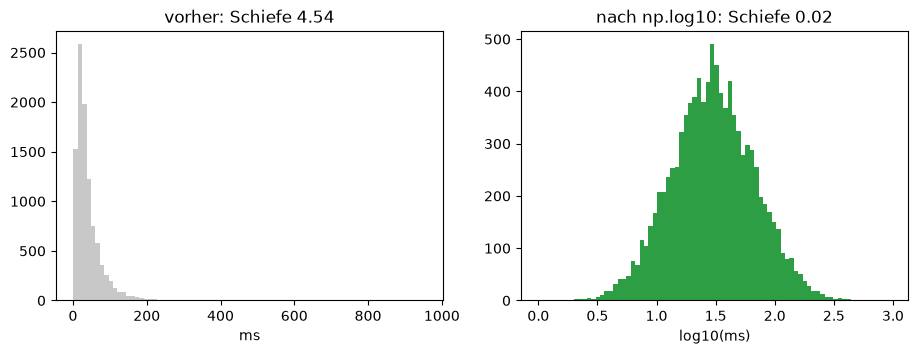

In [153]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(lat, bins=80, color=GRAU)
axes[0].set_title(f"vorher: Schiefe {lat.skew():.2f}")
axes[0].set_xlabel("ms")
axes[1].hist(lg, bins=80, color=GRUEN)
axes[1].set_title(f"nach np.log10: Schiefe {lg.skew():.2f}")
axes[1].set_xlabel("log10(ms)")
plt.show()

<img src="png%20Dateien/der_ausreisser.png" alt="Der Kater" width="100">

**Der Kater:** „Nach dem Logarithmus wohne ich gar nicht mehr so weit draußen."

## 10 – Nullen und Zähldaten: `np.log1p` und `np.sqrt`

Downloads pro Tag: viele Tage mit 0, wenige mit sehr vielen Downloads.

In [154]:
rng = np.random.default_rng(42)
# Mischung negative Binomialverteilung: Gammaverteilung(0.5=Form, 20=Skala(Form*Skala)=0,5*20=10, 365=ein Wert pro Tag): strak rechtsschief
# Ergebnise: 0,02, 0,4, 3,1, 0,00001, 0,04, 4,1 -> poisson macht aus Raten: 0 Downloads, 0 Downloads, 3 Downloads, ...
# poisson e^(-Anzahl) != 0, Varianz=Anzahl, leicht rechtsschief, 
dl = pd.Series(rng.poisson(rng.gamma(0.5, 20, 365)), name="downloads")
print("Tage mit 0:", (dl == 0).sum(), "| Schiefe:", round(dl.skew(), 2))

Tage mit 0: 96 | Schiefe: 2.43


`np.log10(0)` ergibt `-inf` (minus unendlich) mit einer Warnung, aber **ohne Fehler**. Danach sind `mean()` und `skew()` unbrauchbar:

In [155]:
print(np.log10(dl).mean())

-inf


c:\Users\J.Brutskaya\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


Abhilfe: `np.log1p(x)` rechnet ln(1 + x). Aus 0 wird 0. Alternativ die Wurzel `np.sqrt`, die schwächer wirkt.

In [156]:
print(np.log1p(pd.Series([0, 9, 99])).round(3).tolist())
print()
print("Schiefe log1p:", round(np.log1p(dl).skew(), 2))
print("Schiefe sqrt: ", round(np.sqrt(dl).skew(), 2))

[0.0, 2.303, 4.605]

Schiefe log1p: 0.09
Schiefe sqrt:  0.63


Die Rückwege:

| hin | zurück |
|---|---|
| `np.log10(x)` | `10 ** y` |
| `np.log(x)` (das ist **ln**) | `np.exp(y)` |
| `np.log1p(x)` | `np.expm1(y)` |
| `np.sqrt(x)` | `y ** 2` |

### Übung 3

Übungen 5 und 6 vom Vormittag.

- **a)** Fünf Dateien sind 1, 10, 100, 1 000 und 10 000 KB groß. Lege sie als Series an und berechne Mittelwert und Median.
- **b)** Berechne `np.log10` der Größen, den Mittelwert der Logarithmen und rechne ihn zurück. Mit welchem Wert aus a) stimmt er überein?
- **c)** Lege eine Tabelle mit den Spalten `original`, `log1p` und `sqrt` an, die die Schiefe von `dl` vergleicht. Welche Transformation passt für Downloads mit vielen Nullen?
- **d)** Wie viele Werte von `np.log10(dl)` sind `-inf`? *Hinweis: `np.isinf`.*

In [157]:
# a)
dateien = pd.Series([1, 10, 100, 1000, 10_000])
print(round(dateien.mean(), 1), dateien.median())

2222.2 100.0


In [158]:
# b) Log und zurück
log_dateien = np.log10(dateien)
print(log_dateien.tolist())
print(log_dateien.mean(), 10 ** log_dateien.mean()) # 100 wie Median aus a)

[0.0, 1.0, 2.0, 3.0, 4.0]
2.0 100.0


In [159]:
# c) Schiefe vergleichen
pd.Series({"original": dl.skew(), "log1p": np.log1p(dl).skew(), "sqrt": np.sqrt(dl).skew()}).round(2)


original    2.43
log1p       0.09
sqrt        0.63
dtype: float64

In [160]:
# d) -inf, genau die Tagen mit o Downloads
print(np.isinf(np.log10(dl)).sum())

96


c:\Users\J.Brutskaya\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


---
# Block D – Parameter schätzen

## 11 – Schätzer sind einfache Kennzahlen

<img src="png%20Dateien/herr_bauchgefuehl.png" alt="Herr Bauchgefühl" width="110">

> **Herr Bauchgefühl:** „Ich habe 5 Testpakete geschickt, 3 sind angekommen. Die Leitung liefert also 60 % aller Pakete aus. Fertig."

Die Maximum-Likelihood-Schätzer aus dem Skript sind in Pandas eine Zeile: p̂ = Anteil, λ̂ = Mittelwert (Poisson) oder 1 / Mittelwert (Exponential), μ̂ = Mittelwert.

In [161]:
rng = np.random.default_rng(1)
pakete = pd.Series(rng.random(200) < 0.97)          # True = angekommen, wahre Verlustquote 3 %
print("p̂ Verlust:", round(1 - pakete.mean(), 3))

p̂ Verlust: 0.035


Der Schätzer 0,035 liegt nah an den wahren 3 %, aber nicht genau darauf. Eine Schätzung ist nie exakt.

Mit dem Ticket-Log aus Notebook 11 schätzen wir λ auf zwei Wegen: über die Tickets pro Stunde (Poisson) und über die Abstände (Exponential).

In [162]:
rng = np.random.default_rng(3)
luecken = rng.exponential(scale=15, size=3500)         # Lambda 60/15= 4 Tikets pro Std., 3500 inkl. puffer = 4 Wochen, rund um die Uhr, 7 Wochentagen 
# np.cumsum(luecken) = Zeitpunkte seit dem Start
# lücke 9,4     2,1     31,0
# cumsum9,4     11,5    42,5
# to_timedelta macht cumsum Werte zu Zeitdaer in Min.
log = pd.DataFrame({"zeit": pd.Timestamp("2026-10-26 08:00") + pd.to_timedelta(np.cumsum(luecken), unit="min")}) # -> echte Zeit Stempel
log = log[log["zeit"] < "2026-11-23"] # -> 4 Wochen, 2664 Tickets

# resample braucht zeit von set_index("zeit") als Index
# resample("h") teit in Std.
# size() zählt Tickets
pro_h = log.set_index("zeit").resample("h").size()      # Anzahl -> Poisson

# log["zeit"] - Zeitstempel
# diff() - Zeitdauer (Timedelta)  -> NaT, Min, Sek
# dt.total_seconds() - Zahl in Sek. -> NaN, 126,1815
# div(60) - Zahl in Min.    
warte = log["zeit"].diff().dt.total_seconds().div(60)   # Abstäde -> Exponential

print("λ̂ Poisson:     ", round(pro_h.mean(), 2), "Tickets pro Stunde")          # Lambda^ = Mittelwert der Zählwerte (Poisson)
print("λ̂ Exponential: ", round(60 / warte.mean(), 2), "Tickets pro Stunde")     # Lambda^ = 1/ Mittelwert

λ̂ Poisson:      4.01 Tickets pro Stunde
λ̂ Exponential:  4.01 Tickets pro Stunde


Beide Wege liefern fast dasselbe λ̂ ≈ 4. Neu ist `.div(60)`, die Methode für „geteilt durch". Sie passt gut in Ketten.

## 12 – Die Likelihood als Gitter-Suche

Im Skript wurde das Maximum von L(p) = 10 · p³ · (1 − p)² gesucht (3 von 5 Paketen). Statt abzuleiten probieren wir einfach 101 Werte für p aus und nehmen den besten. `argmax()` gibt die **Position** des größten Werts, bei Pandas gibt `idxmax()` den **Index**.

In [163]:
p = np.linspace(0, 1, 1001).round(2)
# p**3 -> 3 Pakete sind angekommen
# (1-p)**2 -> 2 Pakete verloren 
# 10 = 5 über 3 Binomialkoeffizient
L = 10 * p**3 * (1 - p)**2
print("bestes p:", p[L.argmax()], "| L:", round(L.max(), 4))

lik = pd.DataFrame({"p": p, "L": L})
print(lik.loc[lik["L"].idxmax()])

bestes p: 0.6 | L: 0.3456
p    0.6000
L    0.3456
Name: 595, dtype: float64


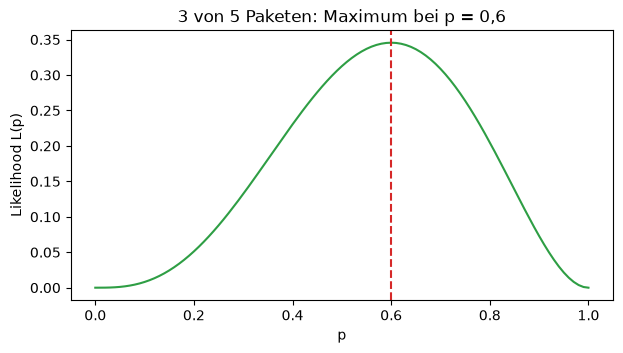

In [164]:
ax = lik.plot(x="p", y="L", figsize=(7, 3.5), legend=False, color=GRUEN)
ax.axvline(0.6, color=ROT, linestyle="--")
ax.set_ylabel("Likelihood L(p)")
ax.set_title("3 von 5 Paketen: Maximum bei p = 0,6")
plt.show()

**Underflow live:** Bei vielen Datenpunkten wird das Produkt so klein, dass der Computer 0 daraus macht. Mit dem Logarithmus wird aus dem Produkt eine Summe.

In [165]:
print(0.5 ** 2000)
print(0.5 ** 1074)
print(0.5 ** 1075)
print(2000 * np.log(0.5))

0.0
5e-324
0.0
-1386.2943611198905


````python
print(2000 * np.log(0.5))
````
np.log ist ln(0,5)= -0,693

ln(a*b) = ln(a) + ln(b)

ln(0,5^2000)=2000 * ln(0,5)= -1386


Likelihood für k von m

$$L(p) = \binom{m}{k} \cdot p^k \cdot (1-p)^{m-k}$$

logaritmiert

$$\ln L(p) = \ln\binom{m}{k} + k \cdot \ln(p) + (m-k) \cdot \ln(1-p)$$

k * np.log(p)           -> k * ln(p)

(m - k) * np.log(1-p)   -> (m - k) * ln(1-p)

In [166]:
k, m = 300, 500
# Binomialkoeffizient ist verschwumden, weil der die Kurve nach oben/unten schiebt, Max bleibt an derselbem Stelle
# np.clip = abschneidet
logL = k * np.log(np.clip(p, 1e-12, 1)) + (m - k) * np.log(np.clip(1 - p, 1e-12, 1))

print("bestes p mit Log-Likelihood:", p[logL.argmax()])

bestes p mit Log-Likelihood: 0.6


`np.clip(p, 1e-12, 1)` verhindert `np.log(0)` an den Rändern p = 0 und p = 1. Das Maximum liegt an derselben Stelle, weil der Logarithmus die Reihenfolge nicht ändert.

## 13 – Durch n oder durch n − 1?

Der ML-Schätzer für σ teilt durch n. Die übliche Standardabweichung teilt durch n − 1. Pandas und NumPy machen es unterschiedlich:

In [167]:
fuenf = pd.Series([44, 47, 43, 46, 45])
print("Pandas std():        ", round(fuenf.std(), 3), "  (n - 1)")
print("Pandas std(ddof=0):  ", round(fuenf.std(ddof=0), 3), "  (n)")
print("NumPy np.std():      ", round(np.std(fuenf), 3), "  (n)")

Pandas std():         1.581   (n - 1)
Pandas std(ddof=0):   1.414   (n)
NumPy np.std():       1.414   (n)


> **Achtung:** `ddof` heißt „delta degrees of freedom": geteilt wird durch n − ddof. Pandas nimmt standardmäßig `ddof=1`, NumPy `ddof=0`. Bei großen Datenmengen ist der Unterschied klein, bei 5 Werten nicht.

## 14 – Mehr Daten, genauere Schätzung

<img src="png%20Dateien/mats_maulwurf_huegel.png" alt="Mats" width="110">

**Mats:** „Bei 5 Paketen? Schick 500, dann glaube ich dir die 60 % eher."

Wir ziehen 1000-mal eine Stichprobe aus `lat` und schauen, wie stark der Mittelwert von Stichprobe zu Stichprobe schwankt. `random_state=i` sorgt dafür, dass jede Wiederholung eine **andere** Stichprobe zieht.

In [168]:
for m in (5, 50, 500):
    mittel = [lat.sample(m, random_state=i).mean() for i in range(1000)]
    print(f"Stichprobe {m:>3}: Mittelwerte streuen um ±{np.std(mittel):.1f} ms")

Stichprobe   5: Mittelwerte streuen um ±16.6 ms
Stichprobe  50: Mittelwerte streuen um ±5.7 ms
Stichprobe 500: Mittelwerte streuen um ±1.8 ms


10-mal mehr Daten machen die Schätzung rund 3-mal genauer (√10 ≈ 3,2).

## 15 – Ausblick: Bootstrap

In der Praxis hat man nur **eine** Stichprobe. Der Bootstrap-Trick: Aus dieser einen Stichprobe ziehen wir viele neue, **mit Zurücklegen** und in **gleicher Größe** (`frac=1, replace=True`). Jede Ziehung ist eine leicht andere Version der Daten.

In [169]:
klein = lat.sample(50, random_state=1)

boot = pd.Series([klein.sample(frac=1, replace=True, random_state=i).median() for i in range(1000)])

print("Median der Stichprobe:", klein.median())
print("95 % der Bootstrap-Mediane liegen zwischen", boot.quantile([0.025, 0.975]).round(1).tolist())

Median der Stichprobe: 31.85
95 % der Bootstrap-Mediane liegen zwischen [23.4, 54.0]


Daraus wird im nächsten Kapitel das **Konfidenzintervall**. Heute nur als Vorschau, ohne Formel.

> **Achtung:** Ohne `random_state=i` (oder mit immer demselben Wert) ziehen alle 1000 Wiederholungen dieselbe Stichprobe, und das Intervall schrumpft auf einen Punkt.

### Übung 4

Übungen 7 und 8 vom Vormittag.

- **a)** Schätze mit Pandas: (1) die Verlustquote, wenn von 200 Paketen 6 verloren gingen, (2) λ aus den Tickets pro Stunde 3, 5, 4, 2, 6, 4, (3) λ pro Stunde, wenn zwischen zwei Alarmen im Mittel 12 Minuten vergehen, (4) μ aus den Latenzen 44, 47, 43, 46, 45.
- **b)** Von 10 Paketen sind 3 fehlerhaft: L(p) = 120 · p³ · (1 − p)⁷. Woher kommt die 120? Prüfe mit `math.comb`.
- **c)** Berechne L(p) auf einem Gitter von 0 bis 1 in Schritten von 0,01 und lies L(0,1), L(0,3) und L(0,5) ab. *Hinweis: `lik.set_index("p").loc[[0.1, 0.3, 0.5]]`.*
- **d)** Bestimme den ML-Schätzer mit `idxmax` und zeichne die Kurve.

In [170]:
# a)
# (1) die Verlustquote, wenn von 200 Paketen 6 verloren gingen
verlust = pd.Series([True] * 6 + [False]  * 194)                # True = verloren
print("Verlust p^", verlust.mean())

# (2) λ aus den Tickets pro Stunde 3, 5, 4, 2, 6, 4
tickets = pd.Series([3, 5, 4, 2, 6, 4])
print("Poisson Lambda^", tickets.mean())

# (3) λ pro Stunde, wenn zwischen zwei Alarmen im Mittel 12 Minuten vergehen 
print("Exponential 1/Lambda^", 60/12)

# (4) μ aus den Latenzen 44, 47, 43, 46, 45
latenz = pd.Series([44, 47, 43, 46, 45])
print("Normalverteilung Mü^", latenz.mean())

Verlust p^ 0.03
Poisson Lambda^ 4.0
Exponential 1/Lambda^ 5.0
Normalverteilung Mü^ 45.0


In [171]:
# b) Anzahl der Möglichkeiten, 3 fehlhaft unter 10 -> Verteilung? Binomialvcerteilung
# L(p) = 120 · p³ · (1 − p)⁷ -> 120 ist Binomialkoeffizient
from math import comb
print(comb(10, 3))



120


In [172]:
# c) gitter und 3 p ablesen
p = np.linspace(0, 1, 101).round(2)
lik = pd.DataFrame({"p": p, "L": 120 * p**3 * (1 - p)**7})
lik.set_index("p").loc[[0.1, 0.3, 0.5]].round(3)


,L
p,
0.1,0.057
0.3,0.267
0.5,0.117


ML-Schätzer 0.3


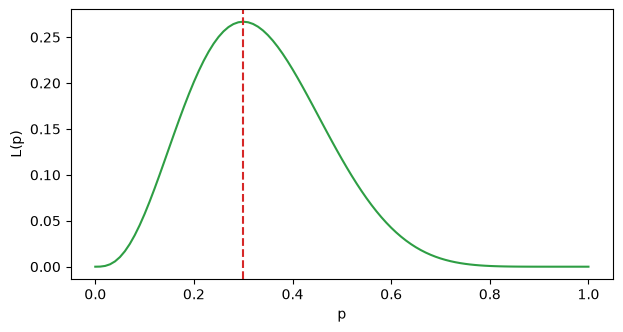

In [173]:
# d) Max und Kurve
print("ML-Schätzer", lik.loc[lik["L"].idxmax(), "p"])

ax = lik.plot(x="p", y="L", figsize=(7, 3.5), legend=False, color=GRUEN)
ax.axvline(0.3, color=ROT, linestyle="--")
ax.set_ylabel("L(p)")
plt.show()


---
# Block E – Monte-Carlo vektorisiert

## 16 – π mit einer Million Darts

<img src="png%20Dateien/fiete_fuchs.png" alt="Fiete Fuchs" width="110">

**Fiete Fuchs:** „Monte Carlo ist ein berühmtes Casino in Monaco. Einzelne Spiele sind reiner Zufall, aber über Millionen Spiele weiß die Bank sehr genau, was sie verdient."

Neu ist ein **2D-Array**: `rng.random((1_000_000, 2))` hat eine Million Zeilen und zwei Spalten. Jede Zeile ist ein Punkt (x, y). `sum(axis=1)` summiert **pro Zeile** über die Spalten, also x² + y² für jeden Punkt. Keine Schleife nötig.

In [174]:
rng = np.random.default_rng(1)
xy = rng.random((1_000_000, 2))
print(xy.shape)

print(xy[:3].round(3))
# Pythagoras x^2 + y^2 <=1
innen = (xy ** 2).sum(axis=1) <= 1
print()
print("π ≈", 4 * innen.mean())     # Pi = 1,31416, innen.mean()=0,7858

# 100       +/-0,16
# 10_000    +/-0,016
# 1_000_000 +/-0,0016

(1000000, 2)
[[0.512 0.95 ]
 [0.144 0.949]
 [0.312 0.423]]

π ≈ 3.143196


> **Achtung:** `sum(axis=1)` summiert pro Zeile, `sum(axis=0)` (der Standard) pro Spalte. Mit `axis=0` kämen zwei Zahlen heraus statt einer Million.

## 17 – Die Projektdauer simulieren

Das Projekt aus dem Skript: drei Phasen, jede mit Best Case, wahrscheinlichstem Wert und Worst Case. Dafür gibt es die **Dreiecksverteilung** `rng.triangular(links, modus, rechts, size)`.

| Phase | Best | meistens | Worst |
|---|---|---|---|
| Konzept | 3 | 5 | 8 |
| Programmierung | 10 | 15 | 30 |
| Test | 4 | 6 | 12 |

> **Achtung:** Die Reihenfolge ist Minimum, **Modus**, Maximum, nicht Minimum, Maximum, Modus.

In [175]:
rng = np.random.default_rng(1)
n = 100_000
phasen = pd.DataFrame({
    "konzept":        rng.triangular(3, 5, 8, n),
    "programmierung": rng.triangular(10, 15, 30, n),
    "test":           rng.triangular(4, 6, 12, n),
})
proj = phasen.assign(dauer=lambda d: d.sum(axis=1),
                     kosten=lambda d: d["dauer"] * 1500)
proj.mean().round(1)

konzept               5.3
programmierung       18.3
test                  7.3
dauer                31.0
kosten            46476.3
dtype: float64

Die Mittelwerte passen zur Faustregel aus dem Skript: Mittel einer Dreiecksverteilung = Durchschnitt der drei Werte, zum Beispiel (10 + 15 + 30) / 3 = 18,3.

Jetzt die eigentlichen Fragen: Wie wahrscheinlich halten wir 30 Tage, und welchen Termin nennen wir?

In [176]:
print("P(fertig in 26 Tagen):", round((proj["dauer"] <= 26).mean(), 3))
print("P(fertig in 30 Tagen):", round((proj["dauer"] <= 30).mean(), 3))
print()
print(proj["dauer"].quantile([0.5, 0.75, 0.9, 0.95]).round(1))
print()
print("Budget mit 95 % Sicherheit:", proj["kosten"].quantile(0.95).round(-2), "€")

P(fertig in 26 Tagen): 0.144
P(fertig in 30 Tagen): 0.456

0.50    30.5
0.75    34.2
0.90    37.5
0.95    39.3
Name: dauer, dtype: float64

Budget mit 95 % Sicherheit: 58900.0 €


Die Summe der wahrscheinlichsten Werte ist 5 + 15 + 6 = 26 Tage. Die hält nur in rund 14 % der Fälle. Der lange Ausläufer bei der Programmierung zieht alles nach rechts.

**Kurzform:** `rng.triangular` nimmt auch **Listen** als Parameter. Mit `size=(n, 3)` entstehen alle drei Phasen auf einmal, eine Spalte pro Phase:

In [177]:
rng2 = np.random.default_rng(1)
dauer = rng2.triangular([3, 10, 4], [5, 15, 6], [8, 30, 12], size=(n, 3)).sum(axis=1)
print(round(dauer.mean(), 2), round((dauer <= 30).mean(), 3))

30.98 0.458


Andere Reihenfolge der Zufallszahlen, deshalb leicht andere Werte, aber dieselbe Aussage.

## 18 – Das Ergebnis in Klassen und als Kurve

`pd.cut` mit `labels` gibt den Klassen lesbare Namen:

In [178]:
klassen = pd.cut(proj["dauer"], bins=[0, 26, 30, 34, 40, 60],           # (0, 26]
                 labels=["≤26", "26–30", "30–34", "34–40", ">40"])
klassen.value_counts(normalize=True).sort_index().round(3)

dauer
≤26      0.144
26–30    0.312
30–34    0.283
34–40    0.224
>40      0.036
Name: proportion, dtype: float64

Die **ECDF** (empirische Verteilungsfunktion) beantwortet die Frage der Chefin direkt: „Mit welcher Wahrscheinlichkeit sind wir nach x Tagen fertig?" Das ist F(x) aus Skript 4, hier aus Simulationsdaten: Werte sortieren, und der i-te Wert bekommt den Anteil i / n.

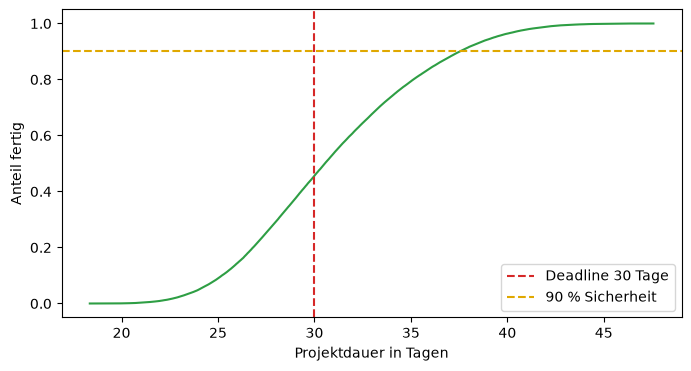

In [179]:
# Ausschnitt aus 100_000 Projektabläufen (Stichprobe n=5). SORTIERT!!!!
#     Projekte -> 24     29   31      33     38
# Anteil i/n   -> 0,2   0,4   0,6    0,8     1,0
#                 |
#                 nach 24 Tagen sind wir mit 20% fertig  




d = proj["dauer"].sort_values().to_numpy()
anteil = np.arange(1, len(d) + 1) / len(d)      # len(d)=100_000, Ergebnis: 0,00001, 0,0002, 0,00003 ... 1

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(d, anteil, color=GRUEN)                                     # F(x)= P(X<=x) - Verteilungsfunktion
ax.axvline(30, color=ROT, linestyle="--", label="Deadline 30 Tage")
ax.axhline(0.9, color=GELB, linestyle="--", label="90 % Sicherheit")
ax.set_xlabel("Projektdauer in Tagen")
ax.set_ylabel("Anteil fertig")
ax.legend()
plt.show()

### Übung 5

Das Team ergänzt eine vierte Phase **Deployment** mit Best 1, meistens 2 und Worst 6 Tagen.

- **a)** Simuliere alle vier Phasen mit 100 000 Durchläufen (`rng = np.random.default_rng(1)`). Berechne Dauer und Kosten (1 500 € pro Tag) mit `assign`.
- **b)** Wie wahrscheinlich hält jetzt die Deadline von 30 Tagen? Wie viel schlechter ist das als ohne Deployment?
- **c)** Welchen Termin und welches Budget nennst du der Chefin mit 90 % Sicherheit?
- **d)** Zeichne die ECDF mit und ohne Deployment in eine Grafik.

In [180]:
# a) 4 Phasen, Kette mit .assign
rng = np.random.default_rng(1)
proj4 = (
    pd.DataFrame({
        "konzept":          rng.triangular(3, 5, 8, n),
        "programmierung":   rng.triangular(10, 15, 30, n),
        "test":             rng.triangular(4, 6, 12, n),
        "deployment":       rng.triangular(1, 2, 6, n),
    })
    .assign(dauer=lambda d: d.sum(axis=1),
            kosten=lambda d: d["dauer"] * 1500)
)
proj4.mean().round(1)
proj4.head()


,konzept,programmierung,test,deployment,dauer,kosten
0,5.293956,16.216250,7.371844,3.164676,32.046726,48070.088741
1,7.138000,20.509164,7.703484,3.553264,38.903911,58355.866461
2,4.200665,16.647461,5.841525,2.815428,29.505078,44257.617287
3,7.122356,19.225412,8.290040,2.811174,37.448983,56173.474419
4,4.765875,16.060235,5.319988,1.960770,28.106868,42160.302386


In [181]:
# b) deadline 30 T.
print("mit Deployment", round((proj4["dauer"] <= 30).mean(), 3))
print("ohne Deployment", round((proj["dauer"] <= 30).mean(), 3))


mit Deployment 0.219
ohne Deployment 0.456


In [182]:
# c) 90-%-Perzentil
print("Termin", round(proj4["dauer"].quantile(0.9), 1))
print("Budget", proj4["kosten"].quantile(0.9).round(-2))


Termin 40.6
Budget 61000.0


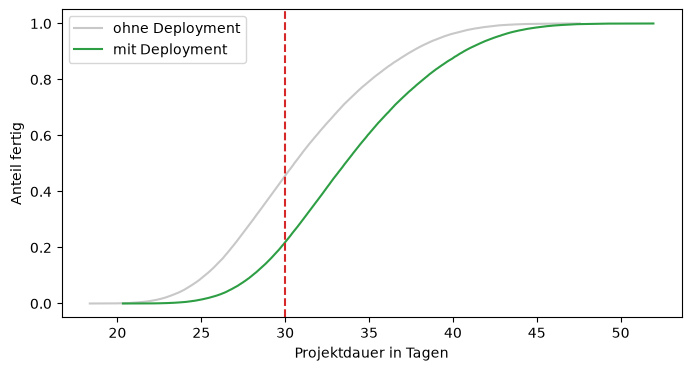

In [208]:
# d) 2 ECDFs
fig, ax = plt.subplots(figsize=(8, 4))
for name, daten, farbe in [("ohne Deployment", proj["dauer"], GRAU), ("mit Deployment", proj4["dauer"], GRUEN)]:
    werte = daten.sort_values().to_numpy()
    ax.plot(werte, np.arange(1, len(werte) + 1) / len(werte), color=farbe, label=name)
ax.axvline(30, color=ROT, linestyle="--")
ax.set_xlabel("Projektdauer in Tagen")
ax.set_ylabel("Anteil fertig")
ax.legend()
plt.show()


---
# Block F – Weitere Übungen

- **Übung 6:** Kennzahlen lesen (zu Block A)
- **Übung 7:** Underflow und wenig oder viel Daten (zu Block D)
- **Übung 8:** π mit wenigen Darts (zu Block E)
- **Übung 9:** Monte-Carlo mit Stift und Papier (zu Block E)
- **Übung 10:** Ein Simulationsergebnis lesen (zu Block E)
- **Übung 11:** Zusatz: Box-Cox findet den Logarithmus (zu Block C, mit SciPy)

### Übung 6 – Kennzahlen lesen (zu Block A)

Übung 3 vom Vormittag. Führe die Zelle aus: Sie erzeugt vier Datensätze, deren Quellen vertauscht sind.

- **a)** Berechne für jede Spalte Schiefe und Wölbung in einer Tabelle.
- **b)** Ordne zu: Jitter gleichverteilt zwischen 10 und 50 ms, Messfehler eines Sensors, Dateigrößen, Verfügbarkeit in Prozent.
- **c)** Prüfe deine Zuordnung mit einem Histogramm pro Spalte (`df.hist`).

In [184]:
rng = np.random.default_rng(6)
vier = pd.DataFrame({
    "A": rng.normal(0, 0.2, n),
    "B": rng.lognormal(np.log(200), 0.6, n),
    "C": 100 - rng.gamma(5, 0.3, n),
    "D": rng.uniform(10, 50, n),
})

In [185]:
# a)


In [186]:
# b)


In [187]:
# c)


### Übung 7 – Underflow und wenig oder viel Daten (zu Block D)

Übungen 9 und 10 vom Vormittag.

- **a)** Berechne 0,5⁴, den ln davon und 4 · ln(0,5).
- **b)** Berechne 0,5²⁰⁰⁰ und 2000 · ln(0,5). Was ist beim ersten Wert passiert?
- **c)** Test A: 3 von 5 Paketen kamen an. Test B: 300 von 500. Berechne für beide die Log-Likelihood auf einem Gitter. Damit beide Kurven vergleichbar sind, rechne `np.exp(logL - logL.max())` (Maximum = 1) und zeichne beide in eine Grafik.
- **d)** Herr Bauchgefühl: „Beide Schätzungen sind 60 %, also sind sie gleich gut." Stimmt das?

In [188]:
# a)


In [189]:
# b)


In [190]:
# c)


In [191]:
# d)


### Übung 8 – π mit wenigen Darts (zu Block E)

Übung 11 vom Vormittag. Eine Kollegin kommt mit 100 Punkten auf 3,24.

- **a)** Schreibe eine Funktion `pi_schaetzen(anzahl, seed)`, die π mit `anzahl` Punkten schätzt.
- **b)** Schätze π je 1000-mal mit 100 und mit 10 000 Punkten (`seed` = 0 bis 999). Wie stark streuen die Ergebnisse (`np.std`)?
- **c)** Hat die Kollegin falsch gerechnet? Wie viele Punkte braucht man, um 10-mal genauer zu werden?

In [192]:
# a)


In [193]:
# b)


In [194]:
# c)


### Übung 9 – Monte-Carlo mit Stift und Papier (zu Block E)

Übung 12 vom Vormittag: fünf schon gezogene Durchläufe, Deadline 30 Tage.

- **a)** Lege die Tabelle als DataFrame an und ergänze die Spalten `summe` und `gehalten` mit `assign`.
- **b)** In wie viel Prozent der Durchläufe wird die Deadline gehalten? Wie lang ist die mittlere Dauer?
- **c)** Warum reichen fünf Durchläufe nicht?

In [195]:
laeufe = pd.DataFrame({
    "konzept":        [4, 6, 5, 7, 4],
    "programmierung": [14, 22, 16, 27, 12],
    "test":           [6, 7, 9, 8, 5],
}, index=[1, 2, 3, 4, 5])

In [196]:
# a)


In [197]:
# b)


In [198]:
# c)


### Übung 10 – Ein Simulationsergebnis lesen (zu Block E)

<img src="png%20Dateien/herr_bauchgefuehl_verdutzt.png" alt="Herr Bauchgefühl stutzt" width="110">

Übung 13 vom Vormittag. Benutze `proj` aus Abschnitt 17.

- **a)** Die Chefin will einen Termin, der mit 90 % Sicherheit hält. Welchen Termin und welches Budget nennst du?
- **b)** Das bewilligte Budget beträgt 45 000 €. Wie wahrscheinlich reicht es?
- **c)** Simuliere noch einmal, aber mit der Schätzung des Teams für die Programmierung: 10 / 12 / 14 Tage. Wie wahrscheinlich hält jetzt die Deadline von 30 Tagen? Bei den letzten drei Projekten dauerte die Programmierung 22, 31 und 38 Tage. Was bedeutet das?
- **d)** Herr Bauchgefühl: „100 000 Durchläufe! Das Ergebnis ist also exakt." Was antwortest du?

In [199]:
# a)


In [200]:
# b)


In [201]:
# c)


In [202]:
# d)


### Übung 11 – Zusatz: Box-Cox findet den Logarithmus (zu Block C)

Für Schnelle, mit **SciPy** (falls nötig: `%pip install scipy`, dann Kernel neu starten). Box-Cox probiert viele Potenzen durch und wählt die, nach der die Daten am symmetrischsten sind.

- **a)** Wende `stats.boxcox(lat)` an. Die Funktion gibt zwei Dinge zurück: die transformierten Daten und die gewählte Potenz λ. Welches λ wird gewählt? Was bedeutet λ ≈ 0?
- **b)** Wie groß ist die Schiefe danach?
- **c)** `stats.boxcox(lat - 30)` scheitert. Warum? Probiere `stats.yeojohnson(lat - 30)`.

In [203]:
# a)


In [204]:
# b)


In [205]:
# c)


---
## 19 – Zusammenfassung

| Aufgabe | Befehl |
|---|---|
| Schiefe, Wölbung (Exzess) | `s.skew()`, `s.kurt()` (Normal = 0) |
| mehrere Perzentile | `s.quantile([0.5, 0.9, 0.95, 0.99])` |
| Modus bei stetigen Daten | `pd.cut(s, bins=…).value_counts().idxmax().mid` |
| log-normal ziehen | `rng.lognormal(np.log(median), sigma, n)` |
| Log-Achse | `ax.set_xscale("log")`, Klassen mit `np.logspace` |
| neue Spalten in einer Kette | `df.assign(neu=lambda d: …)` |
| eigene Funktion in einer Kette | `s.pipe(funktion)` |
| Logarithmus | `np.log10` (zurück `10 **`), `np.log` = ln (zurück `np.exp`) |
| bei Nullen | `np.log1p` (zurück `np.expm1`), `np.sqrt` |
| Maximum auf einem Gitter | `x[werte.argmax()]`, `df.loc[df["L"].idxmax()]` |
| Logarithmus ohne log(0) | `np.log(np.clip(p, 1e-12, 1))` |
| Standardabweichung durch n | `s.std(ddof=0)` oder `np.std(s)` |
| Bootstrap | `s.sample(frac=1, replace=True, random_state=i)` |
| 2D-Zufallsarray | `rng.random((n, 2))`, `size=(n, k)` |
| pro Zeile summieren | `arr.sum(axis=1)`, `df.sum(axis=1)` |
| Dreiecksverteilung | `rng.triangular(min, modus, max, n)` |
| Klassen mit Namen | `pd.cut(s, bins=[…], labels=[…])` |
| ECDF | sortieren, dann `np.arange(1, n + 1) / n` |

**Merke:** Bei schiefen Daten Median und Perzentile berichten. Eine Simulation ist nur so gut wie ihre Annahmen.

---
*Material erstellt von Julia Brutskaya | FIDP Daten- und Prozessanalyse*